Cornell Movie-Dialogs Corpus

In [ ]:
!pip -q install convokit tqdm matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
from google.colab import drive
import shutil
import os

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import math
import random
import re
from collections import Counter

import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from convokit import Corpus, download
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

MAX_LENGTH = 30
VOCAB_SIZE = 12000
MIN_FREQ = 2

D_MODEL = 256
NUM_HEADS = 8
NUM_LAYERS = 3
FF_DIM = 1024
DROPOUT = 0.1

BATCH_SIZE = 64
EPOCHS = 15
LEARNING_RATE = 3e-4

SPECIAL_TOKENS = [
    "<pad>", "<sos>", "<eos>", "<unk>"
]


Using device: cuda
GPU: NVIDIA L4


In [ ]:
# Dataset

corpus = Corpus(filename=download("movie-corpus"))

print("Corpus downloaded successfully!")
print("Number of utterances:", len(list(corpus.iter_utterances())))

No configuration file found at /root/.convokit/config.yml; writing with contents: 
# Default Backend Parameters
db_host: localhost:27017
data_directory: ~/.convokit/saved-corpora
model_directory: ~/.convokit/saved-models
default_backend: mem
Corpus downloaded successfully!
Number of utterances: 304713


# Data Preprocessing

In [ ]:
def normalize_text(text):
    text = text.lower().strip()
    text = re.sub(r"[^a-z0-9.,!?'\s]", " ", text)
    text = re.sub(r"([.,!?])", r" \1 ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def extract_pairs(corpus):
    pairs = []

    for utterance in corpus.iter_utterances():
        if utterance.reply_to is None:
            continue

        try:
            parent = corpus.get_utterance(utterance.reply_to)
        except (KeyError, ValueError):
            continue

        if parent is None:
            continue

        if not parent.text or not utterance.text:
            continue

        question = normalize_text(parent.text)
        answer = normalize_text(utterance.text)

        if not question or not answer:
            continue

        if (
            len(question.split()) <= MAX_LENGTH - 2
            and len(answer.split()) <= MAX_LENGTH - 2
        ):
            pairs.append((question, answer))

    return pairs


pairs = extract_pairs(corpus)
random.shuffle(pairs)

split_idx = int(0.9 * len(pairs))
train_pairs = pairs[:split_idx]
val_pairs = pairs[split_idx:]

print("Training pairs:", len(train_pairs))
print("Validation pairs:", len(val_pairs))

print("\nExample conversations:")
for question, answer in train_pairs[:5]:
    print("Question:", question)
    print("Answer:", answer)
    print()

Training pairs: 163748
Validation pairs: 18195

Example conversations:
Question: won't you change your mind , sir ? what can i say to convince you ?
Answer: nothing . to hell with this place and all the people here .

Question: oh , how did you get burnt out ?
Answer: playing with something really hot . yeah .

Question: i got your goddamn money , you little punk . now where's my daughter ?
Answer: i am through fucking around ! drop that fucking briefcase !

Question: so what's it going to be , coogan's or u vayvudoo ?
Answer: i don't care . i'm not staying out late doug .

Question: why ?
Answer: so i can go over there and pick up your things .



In [ ]:
# Vocabulary and Tokenizer

counter = Counter()

for question, answer in train_pairs:
    counter.update(question.split())
    counter.update(answer.split())

word2idx = {
    token: i
    for i, token in enumerate(SPECIAL_TOKENS)
}

for word, freq in counter.most_common():
    if len(word2idx) >= VOCAB_SIZE:
        break

    if freq >= MIN_FREQ:
        word2idx[word] = len(word2idx)

idx2word = {idx: word for word, idx in word2idx.items()}

PAD_IDX = word2idx["<pad>"]
SOS_IDX = word2idx["<sos>"]
EOS_IDX = word2idx["<eos>"]
UNK_IDX = word2idx["<unk>"]

print("Vocabulary size:", len(word2idx))


def encode(text):
    tokens = text.split()[:MAX_LENGTH - 2]

    return (
        [SOS_IDX]
        + [word2idx.get(t, UNK_IDX) for t in tokens]
        + [EOS_IDX]
    )


def decode(indices):
    words = []

    for idx in indices:
        idx = int(idx)

        if idx == EOS_IDX:
            break

        if idx in (SOS_IDX, PAD_IDX):
            continue

        words.append(idx2word.get(idx, "<unk>"))

    text = " ".join(words)
    return re.sub(r"\s+([.,!?])", r"\1", text)


print(encode("hello how are you ?"))

Vocabulary size: 12000
[1, 296, 50, 35, 7, 6, 2]


In [ ]:
# Pytorch dataset

class ChatDataset(Dataset):
    def __init__(self, pairs):
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        question, answer = self.pairs[idx]

        return (
            torch.tensor(encode(question), dtype=torch.long),
            torch.tensor(encode(answer), dtype=torch.long)
        )


def collate_fn(batch):
    questions, answers = zip(*batch)

    questions = nn.utils.rnn.pad_sequence(
        questions,
        batch_first=True,
        padding_value=PAD_IDX
    )

    answers = nn.utils.rnn.pad_sequence(
        answers,
        batch_first=True,
        padding_value=PAD_IDX
    )

    return questions, answers


train_loader = DataLoader(
    ChatDataset(train_pairs),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    ChatDataset(val_pairs),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

src, tgt = next(iter(train_loader))

print("Source shape:", src.shape)
print("Target shape:", tgt.shape)

Source shape: torch.Size([64, 29])
Target shape: torch.Size([64, 29])


In [ ]:
# Positional encoding

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=MAX_LENGTH):
        super().__init__()

        pe = torch.zeros(max_len, d_model)

        position = torch.arange(
            max_len, dtype=torch.float
        ).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2).float()
            * (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

# Transformer Model

In [ ]:
class TransformerChatbot(nn.Module):
    def __init__(
        self,
        vocab_size,
        d_model=D_MODEL,
        num_heads=NUM_HEADS,
        num_layers=NUM_LAYERS,
        ff_dim=FF_DIM,
        dropout=DROPOUT
    ):
        super().__init__()

        self.d_model = d_model

        self.embedding = nn.Embedding(
            vocab_size,
            d_model,
            padding_idx=PAD_IDX
        )

        self.positional_encoding = PositionalEncoding(d_model)
        self.dropout = nn.Dropout(dropout)

        self.transformer = nn.Transformer(
            d_model=d_model,
            nhead=num_heads,
            num_encoder_layers=num_layers,
            num_decoder_layers=num_layers,
            dim_feedforward=ff_dim,
            dropout=dropout,
            batch_first=True
        )

        self.fc_out = nn.Linear(d_model, vocab_size)

    def forward(self, src, tgt):
        src_padding_mask = src.eq(PAD_IDX)
        tgt_padding_mask = tgt.eq(PAD_IDX)

        src_emb = self.dropout(
            self.positional_encoding(
                self.embedding(src) * math.sqrt(self.d_model)
            )
        )

        tgt_emb = self.dropout(
            self.positional_encoding(
                self.embedding(tgt) * math.sqrt(self.d_model)
            )
        )

        tgt_mask = nn.Transformer.generate_square_subsequent_mask(
            tgt.size(1),
            device=tgt.device
        )

        output = self.transformer(
            src=src_emb,
            tgt=tgt_emb,
            tgt_mask=tgt_mask,
            src_key_padding_mask=src_padding_mask,
            tgt_key_padding_mask=tgt_padding_mask,
            memory_key_padding_mask=src_padding_mask
        )

        return self.fc_out(output)


model = TransformerChatbot(
    vocab_size=len(word2idx)
).to(DEVICE)

num_params = sum(
    p.numel() for p in model.parameters()
)

print(f"Model parameters: {num_params:,}")

Model parameters: 11,686,624


# Training

In [ ]:
criterion = nn.CrossEntropyLoss(
    ignore_index=PAD_IDX
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)


def train_epoch():
    model.train()
    total_loss = 0

    progress = tqdm(train_loader, desc="Training")

    for src, tgt in progress:
        src = src.to(DEVICE)
        tgt = tgt.to(DEVICE)

        # Shift response tokens for teacher forcing
        decoder_input = tgt[:, :-1]
        target_labels = tgt[:, 1:]

        optimizer.zero_grad(set_to_none=True)

        logits = model(src, decoder_input)

        loss = criterion(
            logits.reshape(-1, logits.size(-1)),
            target_labels.reshape(-1)
        )

        loss.backward()

        nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item()

        progress.set_postfix(loss=f"{loss.item():.4f}")

    return total_loss / len(train_loader)


@torch.no_grad()
def evaluate():
    model.eval()
    total_loss = 0

    for src, tgt in val_loader:
        src = src.to(DEVICE)
        tgt = tgt.to(DEVICE)

        logits = model(src, tgt[:, :-1])

        loss = criterion(
            logits.reshape(-1, logits.size(-1)),
            tgt[:, 1:].reshape(-1)
        )

        total_loss += loss.item()

    return total_loss / len(val_loader)

In [ ]:
train_losses = []
val_losses = []

best_val_loss = float("inf")

for epoch in range(EPOCHS):
    train_loss = train_epoch()
    val_loss = evaluate()

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save({
            "model_state_dict": model.state_dict(),
            "word2idx": word2idx,
            "config": {
                "d_model": D_MODEL,
                "num_heads": NUM_HEADS,
                "num_layers": NUM_LAYERS,
                "ff_dim": FF_DIM,
                "dropout": DROPOUT,
                "max_length": MAX_LENGTH
            }
        }, "best_chatbot.pt")

        print("Best model saved!")

print("Training completed!")

Training:   0%|          | 0/2559 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/activation.py:1336: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


Epoch 1/15 | Train Loss: 4.5115 | Validation Loss: 4.1732
Best model saved!


Training:   0%|          | 0/2559 [00:00<?, ?it/s]

Epoch 2/15 | Train Loss: 4.1401 | Validation Loss: 4.0364
Best model saved!


Training:   0%|          | 0/2559 [00:00<?, ?it/s]

... (21 outputs left out)

Training:   0%|          | 0/2559 [00:00<?, ?it/s]

Epoch 14/15 | Train Loss: 3.4755 | Validation Loss: 3.8610


Training:   0%|          | 0/2559 [00:00<?, ?it/s]

Epoch 15/15 | Train Loss: 3.4478 | Validation Loss: 3.8682
Training completed!


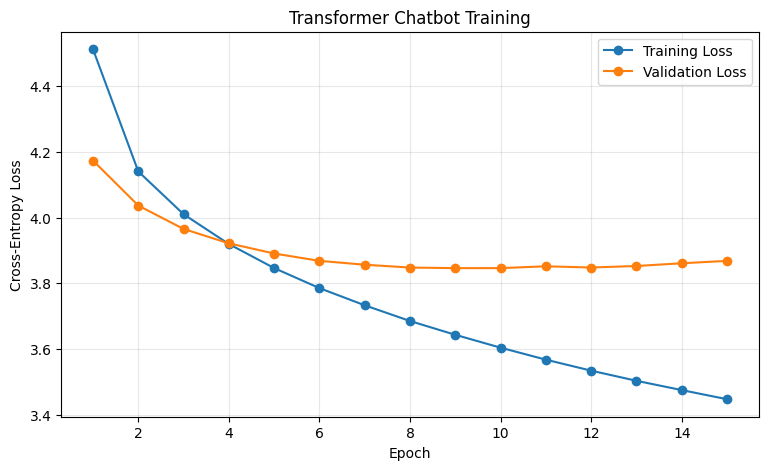

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, len(val_losses) + 1),
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Transformer Chatbot Training")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Testing Chatbot

In [ ]:
checkpoint = torch.load(
    "/content/drive/MyDrive/Colab Notebooks/Data Science/Chat/Youtube Example/best_chatbot.pt",
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Best model loaded!")

Best model loaded!


In [ ]:
# Generating response

@torch.no_grad()
def generate_response(text, temperature=0.8):
    model.eval()

    text = normalize_text(text)

    src = torch.tensor(
        [encode(text)],
        dtype=torch.long,
        device=DEVICE
    )

    generated = torch.tensor(
        [[SOS_IDX]],
        dtype=torch.long,
        device=DEVICE
    )

    for _ in range(MAX_LENGTH - 1):
        logits = model(src, generated)

        next_logits = (
            logits[:, -1, :] / max(temperature, 1e-5)
        )

        # Exclude tokens that should not be generated
        next_logits[:, PAD_IDX] = float("-inf")
        next_logits[:, SOS_IDX] = float("-inf")

        probabilities = torch.softmax(
            next_logits, dim=-1
        )

        next_token = torch.multinomial(
            probabilities,
            num_samples=1
        )

        generated = torch.cat(
            [generated, next_token],
            dim=1
        )

        if next_token.item() == EOS_IDX:
            break

    return decode(generated[0].tolist())

In [ ]:
test_messages = [
    "hello",
    "how are you?",
    "what is your name?",
    "what are you doing?",
    "do you love me?",
    "goodbye"
]

for message in test_messages:
    response = generate_response(message)

    print("You:", message)
    print("Bot:", response)
    print("-" * 40)

You: hello
Bot: who the fuck is he?
----------------------------------------
You: how are you?
Bot: i don't care. it's just something i want to do with the tide.
----------------------------------------
You: what is your name?
Bot: you are your husband.
----------------------------------------
You: what are you doing?
Bot: i'm here for the western.
----------------------------------------
You: do you love me?
Bot: n no, no.
----------------------------------------
You: goodbye
Bot: she's not a boy. and i see if we don't get him into this thing
----------------------------------------


# Chatbot Sandbox

In [ ]:
import ipywidgets as widgets
from IPython.display import display

chat_input = widgets.Text(
    placeholder="Type your message...",
    description="You:",
    layout=widgets.Layout(width="75%")
)

send_button = widgets.Button(
    description="Send",
    button_style="primary"
)

chat_output = widgets.Output()


def send_message(_):
    message = chat_input.value.strip()

    if not message:
        return

    chat_input.value = ""

    response = generate_response(message)

    with chat_output:
        print(f"You: {message}")
        print(f"Bot: {response}")
        print()


send_button.on_click(send_message)

display(
    widgets.VBox([
        widgets.HBox([chat_input, send_button]),
        chat_output
    ])
)

In [ ]:
save_dir = "/content/drive/MyDrive/Colab Notebooks/Data Science/Chat/Youtube Example"
os.makedirs(save_dir, exist_ok=True)

shutil.copy(
    "best_chatbot.pt",
    os.path.join(save_dir, "best_chatbot.pt")
)

print("Model saved to Google Drive!")